In [31]:
# import lab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy. stats import ttest_ind 

In [32]:
df = pd.read_csv('ecommerce_clean_data.csv')

In [33]:
df


,Order_ID,OrderDate,customer_Id,Paymentmethod,orderStatus,customer_name,Gender,Age,City,Region,...,Costprice,Sellingprice,Year,Month,MonthName,Quarter,Day,OrderDayName,YearMonth,Profit_Margin
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,5353.0,10018.0,2026,1,January,1,19,Monday,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,3112.0,5568.0,2026,1,January,1,19,Monday,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,5905.0,10331.0,2026,2,February,1,14,Saturday,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3425.0,4363.0,2026,2,February,1,14,Saturday,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,3999.0,6601.0,2025,11,November,4,21,Friday,2025-11,36.229758
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12553,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,6411.0,9277.0,2026,3,March,1,20,Friday,2026-03,27.256429
12554,O04999,2026-03-20,C0371,Credit Card,Delivered,Customer_0371,Female,46,Lucknow,North,...,2528.0,3517.0,2026,3,March,1,20,Friday,2026-03,15.435950
12555,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,3254.0,4834.0,2025,12,December,4,16,Tuesday,2025-12,20.806055
12556,O05000,2025-12-16,C0777,COD,Delivered,Customer_0777,Male,56,Chennai,South,...,433.0,791.0,2025,12,December,4,16,Tuesday,2025-12,31.573957


In [34]:
df.columns.tolist()

['Order_ID',
 'OrderDate',
 'customer_Id',
 'Paymentmethod',
 'orderStatus',
 'customer_name',
 'Gender',
 'Age',
 'City',
 'Region',
 'SignupDate',
 'OrderDetails_ID',
 'product_ID',
 'Quantity',
 'Unitprice',
 'Discountprice',
 'SalesAmount',
 'Profit',
 'Product_name',
 'Category',
 'Costprice',
 'Sellingprice',
 'Year',
 'Month',
 'MonthName',
 'Quarter',
 'Day',
 'OrderDayName',
 'YearMonth',
 'Profit_Margin']

In [35]:
# Filter delivered orders
test_df = df[
    df['orderStatus'] == 'Delivered'
] .copy()

test_df.head()

,Order_ID,OrderDate,customer_Id,Paymentmethod,orderStatus,customer_name,Gender,Age,City,Region,...,Costprice,Sellingprice,Year,Month,MonthName,Quarter,Day,OrderDayName,YearMonth,Profit_Margin
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,5353.0,10018.0,2026,1,January,1,19,Monday,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,3112.0,5568.0,2026,1,January,1,19,Monday,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,5905.0,10331.0,2026,2,February,1,14,Saturday,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3425.0,4363.0,2026,2,February,1,14,Saturday,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,3999.0,6601.0,2025,11,November,4,21,Friday,2025-11,36.229758


In [36]:
test_df["Discountprice"].describe()

count    10970.000000
mean        10.737922
std          7.095532
min          0.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         25.000000
Name: Discountprice, dtype: float64

In [37]:
#create two groups 
Order_level = (
    test_df
    .groupby("Order_ID")
    .agg(
        Ordervalue=("SalesAmount", "sum"),
        Discountprice=("Discountprice", "mean")
    )
    .reset_index()
)

Order_level.head()

,Order_ID,Ordervalue,Discountprice
0,O00001,49930.00,10.0
1,O00002,25521.25,7.5
2,O00003,12541.90,5.0
3,O00004,41731.20,15.0
4,O00005,57555.85,15.0


In [38]:
#group define 
Order_level

,Order_ID,Ordervalue,Discountprice
0,O00001,49930.00,10.000000
1,O00002,25521.25,7.500000
2,O00003,12541.90,5.000000
3,O00004,41731.20,15.000000
4,O00005,57555.85,15.000000
...,...,...,...
4381,O04995,19430.90,10.000000
4382,O04996,12673.50,7.500000
4383,O04998,24658.60,5.000000
4384,O04999,24078.25,10.000000


In [39]:
discount_group = Order_level[Order_level["Discountprice"] > 0]  ["Ordervalue"]

In [40]:
discount_group 

0       49930.00
1       25521.25
2       12541.90
3       41731.20
4       57555.85
          ...   
4381    19430.90
4382    12673.50
4383    24658.60
4384    24078.25
4385    21834.00
Name: Ordervalue, Length: 4230, dtype: float64

In [41]:
no_discount_group = Order_level[Order_level["Discountprice"] == 0]  ["Ordervalue"]

In [42]:
no_discount_group

28      33435.0
58      31488.0
161     16574.0
181      4367.0
203      7607.0
         ...   
4200    13202.0
4222    21582.0
4290    12456.0
4303    36372.0
4312     3517.0
Name: Ordervalue, Length: 156, dtype: float64

In [43]:
# group mean 
print(
    "Discount median:",
    discount_group .median()
    
)

print(
    " NO Discount median:",
    no_discount_group.median()
    
)

Discount median: 32649.199999999997
 NO Discount median: 14292.0


In [44]:
# visual comparison
# Visual Comparison

comparison_df = pd.DataFrame({
    "AOV": pd.concat(
        [discount_group, no_discount_group],
        ignore_index=True
    ),
    "Group": (
        ["Discount"] * len(discount_group)
        + ["No Discount"] * len(no_discount_group)
    )
})

In [45]:
comparison_df

,AOV,Group
0,49930.00,Discount
1,25521.25,Discount
2,12541.90,Discount
3,41731.20,Discount
4,57555.85,Discount
...,...,...
4381,13202.00,No Discount
4382,21582.00,No Discount
4383,12456.00,No Discount
4384,36372.00,No Discount


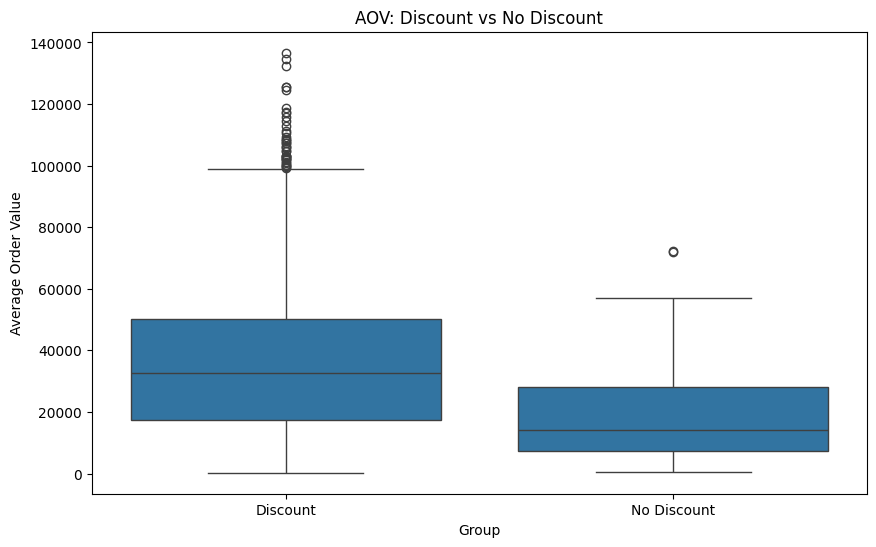

In [46]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=comparison_df,
    x="Group",
    y="AOV"
)

plt.title("AOV: Discount vs No Discount")
plt.xlabel("Group")
plt.ylabel("Average Order Value")

plt.show()

In [47]:
aov_difference = discount_group.mean() - no_discount_group.mean()
aov_difference

np.float64(16751.461486633936)

In [48]:
# Independent t-test

t_stat, p_value = ttest_ind(
    discount_group,
    no_discount_group,
    equal_var=False
)

In [49]:
# Result

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: 13.875792073637808
P-Value: 1.866502282488147e-30


In [50]:
# Decision Rule

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to Reject H0")


Reject H0


In [51]:
from scipy.stats import ttest_ind

result = ttest_ind(
    discount_group,
    no_discount_group,
    equal_var=False
)

print(result)

TtestResult(statistic=np.float64(13.875792073637808), pvalue=np.float64(1.866502282488147e-30), df=np.float64(184.67236156483705))


In [52]:
result.confidence_interval()

ConfidenceInterval(low=np.float64(14369.699005002716), high=np.float64(19133.223968265156))

In [53]:
# Final Hypothesis Testing Summary

hypothesis_result = pd.DataFrame({
    "Metric": [
        "Discount AOV",
        "No Discount AOV",
        "Difference",
        "T-Statistic",
        "P-Value",
        "Alpha"
    ],
    "Value": [
        discount_group.mean(),
        no_discount_group.mean(),
        aov_difference,
        t_stat,
        p_value,
        alpha
    ]
})

hypothesis_result

,Metric,Value
0,Discount AOV,3.555065e+04
1,No Discount AOV,1.879919e+04
2,Difference,1.675146e+04
3,T-Statistic,1.387579e+01
4,P-Value,1.866502e-30
5,Alpha,5.000000e-02
